## Load the data

In [1]:
from pathlib import Path
import pandas as pd

directory = Path("../../data/cryptohftdata/derived/datasets/btcusdt_v2/volume_adapt60s-e794c55e50")
files = sorted(directory.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
).sort_values("bar_id").reset_index(drop=True)


In [2]:
df.shape

(1390444, 666)

In [3]:
import numpy as np

def validate_bars(df, expected_duration_s=60):
    required = [
        "bar_id",
        "decision_time_ns",
        "eval_time_ns",
        "t_start_ns",
        "t_end_ns",
    ]

    assert all(c in df.columns for c in required), "Lipsesc coloane"
    assert len(df) > 0, "DataFrame gol"

    results = []

    def check(name, condition):
        condition = np.asarray(condition, dtype=bool)
        bad = np.flatnonzero(~condition)

        results.append({
            "check": name,
            "status": "PASS" if len(bad) == 0 else "FAIL",
            "errors": len(bad),
        })

        if len(bad):
            print(f"\n{name}: {len(bad):,} erori")
            print("Poziții problematice:", bad[:10])

    check(
        "No missing values",
        ~df[required].isna().any(axis=1).to_numpy()
    )

    ids = df["bar_id"].to_numpy()
    start = df["t_start_ns"].to_numpy()
    end = df["t_end_ns"].to_numpy()
    decision = df["decision_time_ns"].to_numpy()
    evaluation = df["eval_time_ns"].to_numpy()

    check("Unique bar_id", ~df["bar_id"].duplicated().to_numpy())
    check("bar_id ascending", np.r_[True, np.diff(ids) > 0])
    check("bar_id consecutive", np.r_[True, np.diff(ids) == 1])

    check("Start ascending", np.r_[True, np.diff(start) > 0])
    check("End ascending", np.r_[True, np.diff(end) > 0])
    check("Decision ascending", np.r_[True, np.diff(decision) > 0])

    check("Start < End", start < end)
    check("Start <= Evaluation", start <= evaluation)
    check("Evaluation < Decision", evaluation < decision)
    check("End <= Decision", end <= decision)

    check("No overlapping bars", np.r_[True, start[1:] >= end[:-1]])

    if expected_duration_s is not None:
        check(
            "Continuous bars",
            np.r_[True, start[1:] == end[:-1]]
        )
        check(
            "Correct bar duration",
            (end - start) == int(expected_duration_s * 1e9)
        )
        check("Decision == End", decision == end)
        check("Evaluation == Decision - 1 ns", evaluation == decision - 1)

    report = pd.DataFrame(results)

    print("\n=== VALIDATION REPORT ===")
    print(report.to_string(index=False))

    print(f"\nTotal rows: {len(df):,}")
    print(f"Total failed checks: {(report.status == 'FAIL').sum()}")

    return report


report = validate_bars(df)


Start < End: 257 erori
Poziții problematice: [ 2351 19957 21432 23798 24418 42083 47590 52008 55345 57862]

Evaluation < Decision: 1,390,444 erori
Poziții problematice: [0 1 2 3 4 5 6 7 8 9]

Continuous bars: 1,390,442 erori
Poziții problematice: [ 1  2  3  4  5  6  7  8  9 10]

Correct bar duration: 1,390,444 erori
Poziții problematice: [0 1 2 3 4 5 6 7 8 9]

Evaluation == Decision - 1 ns: 1,390,444 erori
Poziții problematice: [0 1 2 3 4 5 6 7 8 9]

=== VALIDATION REPORT ===
                        check status  errors
            No missing values   PASS       0
                Unique bar_id   PASS       0
             bar_id ascending   PASS       0
           bar_id consecutive   PASS       0
              Start ascending   PASS       0
                End ascending   PASS       0
           Decision ascending   PASS       0
                  Start < End   FAIL     257
          Start <= Evaluation   PASS       0
        Evaluation < Decision   FAIL 1390444
              End <= De

In [4]:
df = df.set_index("bar_id", verify_integrity=True)
df = df.sort_index()

print(df.index.is_unique)
print(df.index.is_monotonic_increasing)

True
True


In [5]:
df.head()

,decision_time_ns,eval_time_ns,t_start_ns,t_end_ns,t_open_recv_ns,t_close_recv_ns,m_open_ms,m_close_ms,first_seq,last_seq,...,liq_long_to_bid_depth_10bps_15m,liq_to_trade_notional_1h,liq_to_oi_1h,liq_short_to_ask_depth_10bps_1h,liq_long_to_bid_depth_10bps_1h,activity_vs_ticker24h_2m,activity_vs_ticker24h_15m,activity_vs_ticker24h_1h,rv_ratio_2m_1h_grid1s,liq_any_2m_x_rv_ratio
bar_id,,,,,,,,,,,,,,,,,,,,,
0,1751673614949051593,1751673614949051593,1751673600168116635,1751673614949051593,1751673600168116635,1751673614949051593,1751673600036,1751673614815,12763179,12763717,...,0.0,0.000001,2.516694e-08,0.000004,0.0,0.479480,0.280938,0.342546,0.322259,0.000000
1,1751673707759369793,1751673707759369793,1751673614949057409,1751673707759369793,1751673614949057409,1751673707759369793,1751673614815,1751673707630,12763718,12764608,...,0.0,0.000001,2.516694e-08,0.000004,0.0,0.458360,0.294847,0.340446,0.690113,0.000000
2,1751673720430177868,1751673720430177868,1751673708991403287,1751673720430177868,1751673708991403287,1751673720430177868,1751673708862,1751673720297,12764609,12765198,...,0.0,0.000001,2.516694e-08,0.000004,0.0,0.668627,0.322977,0.347139,1.000185,0.000000
3,1751673734353455417,1751673734353455417,1751673720430182502,1751673734353455417,1751673720430182502,1751673734353455417,1751673720297,1751673734223,12765199,12765648,...,0.0,0.000001,2.516694e-08,0.000004,0.0,0.792583,0.346963,0.352659,1.310321,0.000000
4,1751673772549635923,1751673772549635923,1751673734353480611,1751673772549635923,1751673734353480611,1751673772549635923,1751673734223,1751673772420,12765649,12766535,...,0.0,0.000010,2.513751e-07,0.000041,0.0,0.791350,0.365407,0.357809,2.215952,2.215952


In [6]:
list(df.columns)

['decision_time_ns',
 'eval_time_ns',
 't_start_ns',
 't_end_ns',
 't_open_recv_ns',
 't_close_recv_ns',
 'm_open_ms',
 'm_close_ms',
 'first_seq',
 'last_seq',
 'first_trade_id',
 'last_trade_id',
 'seg',
 'close_reason',
 'complete',
 'threshold_int',
 'feed_complete',
 'bar_open',
 'bar_high',
 'bar_low',
 'bar_close',
 'bar_n_trades',
 'bar_volume_btc',
 'bar_notional_usdt',
 'bar_vwap',
 'bar_return_log',
 'bar_oc_log',
 'bar_range_log',
 'bar_close_location',
 'bar_tfi_btc',
 'bar_tfi_usdt',
 'bar_tfi_ratio',
 'bar_count_imbalance',
 'bar_mean_trade_size_btc',
 'bar_duration_s',
 'bar_volume_rate_btc_s',
 'bar_notional_rate_usdt_s',
 'bar_overshoot_btc',
 'bar_threshold_btc',
 'last_trade_price',
 'last_trade_age_ms',
 'tw_state_5s',
 'tw_state_30s',
 'tw_state_2m',
 'tw_state_15m',
 'tw_state_1h',
 'tw_state_4h',
 'tw_state_24h',
 'trade_count_5s',
 'volume_5s_btc',
 'notional_5s_usdt',
 'trade_rate_5s_per_s',
 'volume_rate_5s_btc_s',
 'notional_rate_5s_usdt_s',
 'tfi_5s_btc',
 

## Create the target

In [7]:
def create_forward_returns(
    df,
    horizons=(1, 2, 3, 5, 10, 20),
    require_feed_complete=False
):
    if "bar_id" in df.columns:
        df = df.set_index("bar_id", verify_integrity=True)
    elif df.index.name != "bar_id":
        raise ValueError("bar_id trebuie să fie coloană sau index.")

    df = df.sort_index()

    ids = df.index.to_numpy(dtype=np.int64)
    n = len(df)

    if n == 0 or np.any(np.diff(ids) <= 0):
        raise ValueError("bar_id invalid.")

    price = df["bar_close"].to_numpy(dtype=np.float64)
    valid_price = np.isfinite(price) & (price > 0)

    log_price = np.full(n, np.nan, dtype=np.float64)
    np.log(price, out=log_price, where=valid_price)

    invalid = ~valid_price

    if "complete" in df.columns:
        invalid |= ~df["complete"].fillna(False).astype(bool).to_numpy()

    if require_feed_complete and "feed_complete" in df.columns:
        invalid |= ~df["feed_complete"].fillna(False).astype(bool).to_numpy()

    breaks = np.zeros(n, dtype=bool)
    breaks[1:] = np.diff(ids) != 1

    if "seg" in df.columns:
        seg = df["seg"].to_numpy()
        breaks[1:] |= seg[1:] != seg[:-1]

    invalid_cumsum = np.cumsum(invalid, dtype=np.int64)
    breaks_cumsum = np.cumsum(breaks, dtype=np.int64)

    # 5. Generarea targeturilor
    targets = pd.DataFrame(index=df.index)

    for k in horizons:
        k = int(k)

        if k < 1:
            raise ValueError("Orizontul trebuie să fie >= 1.")

        y = np.full(n, np.nan, dtype=np.float32)

        if k < n:
            valid = (
                ~invalid[:-k]
                & (invalid_cumsum[k:] == invalid_cumsum[:-k])
                & (breaks_cumsum[k:] == breaks_cumsum[:-k])
            )

            future_return = log_price[k:] - log_price[:-k]

            y[:-k] = np.where(
                valid, future_return, np.nan
            ).astype(np.float32)

        targets[f"ret_{k}fw"] = y

    return df, targets


# Utilizare
df, targets = create_forward_returns(df)

# Adăugare în DataFrame
for col in targets.columns:
    df[col] = targets[col]

print(df[targets.columns].describe())
print(df[targets.columns].isna().mean() * 100)

            ret_1fw       ret_2fw       ret_3fw       ret_5fw      ret_10fw  \
count  1.385400e+06  1.383271e+06  1.381192e+06  1.377190e+06  1.367798e+06   
mean  -2.689698e-07 -4.966337e-07 -7.189960e-07 -1.100696e-06 -1.648031e-06   
std    4.110936e-04  5.837299e-04  7.160970e-04  9.249548e-04  1.307134e-03   
min   -1.086967e-02 -1.048521e-02 -1.061296e-02 -1.186692e-02 -1.195151e-02   
25%   -2.278811e-04 -3.370856e-04 -4.220240e-04 -5.567353e-04 -8.073063e-04   
50%    0.000000e+00  0.000000e+00  0.000000e+00 -8.283973e-07 -7.319759e-06   
75%    2.266157e-04  3.351456e-04  4.194625e-04  5.519762e-04  7.988877e-04   
max    1.253553e-02  1.321421e-02  1.387736e-02  1.781089e-02  1.972091e-02   

           ret_20fw  
count  1.350172e+06  
mean  -2.241470e-06  
std    1.839249e-03  
min   -1.571345e-02  
25%   -1.166878e-03  
50%   -1.626764e-05  
75%    1.143316e-03  
max    2.365867e-02  
ret_1fw     0.362762
ret_2fw     0.515878
ret_3fw     0.665399
ret_5fw     0.953221
ret_10

## EDA

In [8]:
import re
import math
from IPython.display import display

HORIZONS = [1, 2, 3, 5, 10, 20]
TOP_N = 80


MAX_ROWS = 300_000

CHUNK_SIZE = 16
MIN_PAIRS = 1000

targets = [
    f"ret_{h}fw"
    for h in HORIZONS
    if f"ret_{h}fw" in df.columns
]

if not targets:
    raise ValueError("Nu există targeturi forward în df.")

exclude = {
    "bar_id",
    "decision_time_ns",
    "eval_time_ns",
    "t_start_ns",
    "t_end_ns",
    "t_open_recv_ns",
    "t_close_recv_ns",
    "m_open_ms",
    "m_close_ms",
    "first_seq",
    "last_seq",
    "first_trade_id",
    "last_trade_id",
    "seg",
    "close_reason",
    "threshold_int",
    "oi_reference_ts_ns",
    "complete",
    "feed_complete",
}

features = [
    c for c in df.select_dtypes(include=["number", "bool"]).columns
    if c not in exclude
    and not re.match(r"^ret_\d+fw$", c)
    and not re.match(r"^duration_\d+fw_s$", c)
]

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    step = math.ceil(len(df) / MAX_ROWS)
    data = df.iloc[::step]
else:
    data = df

print(f"Observații analizate: {len(data):,}")
print(f"Features analizate: {len(features)}")
print(f"Targets: {targets}")

corr_table = pd.DataFrame(index=features, columns=targets, dtype=float)
n_table = pd.DataFrame(index=features, columns=targets, dtype=float)

for start in range(0, len(features), CHUNK_SIZE):
    cols = features[start:start + CHUNK_SIZE]

    X = data[cols].astype("float64")
    X = X.replace([np.inf, -np.inf], np.nan)

    for target in targets:
        y = pd.to_numeric(data[target], errors="coerce")
        y = y.replace([np.inf, -np.inf], np.nan)

        corr = X.corrwith(y, method="pearson")
        counts = X.notna().mul(y.notna(), axis=0).sum()

        corr_table.loc[cols, target] = corr
        n_table.loc[cols, target] = counts

corr_table = corr_table.mask(n_table < MIN_PAIRS)

top40_by_target = {}

for target in targets:
    top = (
        corr_table[target]
        .dropna()
        .sort_values(key=lambda x: x.abs(), ascending=False)
        .head(TOP_N)
        .to_frame(name="correlation")
    )

    top["abs_corr"] = top["correlation"].abs()
    top["n_pairs"] = n_table.loc[top.index, target].astype(int)
    top["coverage_pct"] = (
        top["n_pairs"] / data[target].notna().sum() * 100
    )

    top40_by_target[target] = top

    print(f"\n===== TOP {TOP_N}: {target} =====")
    display(top.round(5))


max_abs_corr = corr_table.abs().max(axis=1)

top40_features = (
    max_abs_corr
    .dropna()
    .nlargest(TOP_N)
    .index
    .tolist()
)

top40_global = corr_table.loc[top40_features].copy()
top40_global.insert(
    0, "max_abs_corr",
    max_abs_corr.loc[top40_features]
)

print("\n===== TOP 40 GLOBAL =====")
display(top40_global.round(5))

Observații analizate: 278,089
Features analizate: 647
Targets: ['ret_1fw', 'ret_2fw', 'ret_3fw', 'ret_5fw', 'ret_10fw', 'ret_20fw']


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/numpy/lib/_function_base_imp


===== TOP 80: ret_1fw =====


,correlation,abs_corr,n_pairs,coverage_pct
run_sign,0.15167,0.15167,277040,100.00000
tfi_ratio_5s,0.10523,0.10523,276606,99.84334
close_location_5s,0.08609,0.08609,276405,99.77079
qi_1bps,0.08063,0.08063,264458,95.45842
qi_top5,0.07940,0.07940,265386,95.79339
...,...,...,...,...
mlofi_l4_5s_btc,0.01349,0.01349,263243,95.01985
bv_trade_5s_grid100ms,0.01301,0.01301,276601,99.84154
mlofi_l1_30s_btc,0.01299,0.01299,258573,93.33418
mlofi_l2_5s_btc,0.01294,0.01294,263274,95.03104



===== TOP 80: ret_2fw =====


,correlation,abs_corr,n_pairs,coverage_pct
run_sign,0.11475,0.11475,276661,100.00000
tfi_ratio_5s,0.08089,0.08089,276236,99.84638
close_location_5s,0.06528,0.06528,276035,99.77373
count_imbalance_5s,0.05758,0.05758,276236,99.84638
qi_1,0.05415,0.05415,265164,95.84437
...,...,...,...,...
min_depth_bid_5bps_1s_btc,0.01156,0.01156,264184,95.49015
bv_trade_30s_grid100ms,0.01135,0.01135,274535,99.23155
ret_trade_minus_index_30s,0.01117,0.01117,267862,96.81957
depth_bid_top20_btc,0.01110,0.01110,265103,95.82232


... (6 outputs left out)


===== TOP 80: ret_20fw =====


,correlation,abs_corr,n_pairs,coverage_pct
run_sign,0.03428,0.03428,270009,100.00000
qi_25bps,0.02059,0.02059,245291,90.84549
ret_index_2m,-0.01933,0.01933,260264,96.39086
ret_mark_2m,-0.01932,0.01932,260264,96.39086
tfi_ratio_5s,0.01923,0.01923,269684,99.87963
...,...,...,...,...
tw_basis_mid_mark_bps_30s,-0.01128,0.01128,246092,91.14215
tfi_ratio_x_ret_trade_30s,0.01126,0.01126,268383,99.39780
bv_trade_1h_grid1s,0.01125,0.01125,225350,83.46018
pressure_net_5bps_2m,-0.01123,0.01123,243362,90.13107



===== TOP 40 GLOBAL =====


,max_abs_corr,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
run_sign,0.15167,0.15167,0.11475,0.09370,0.07136,0.05077,0.03428
tfi_ratio_5s,0.10523,0.10523,0.08089,0.06604,0.05029,0.03325,0.01923
close_location_5s,0.08609,0.08609,0.06528,0.05429,0.04212,0.02892,0.01702
qi_1bps,0.08063,0.08063,0.05255,0.04119,0.02996,0.01844,0.01000
qi_top5,0.07940,0.07940,0.05367,0.04303,0.03151,0.02033,0.01339
...,...,...,...,...,...,...,...
max_spread_bps_1s,0.01540,-0.00069,0.00691,0.00989,0.00891,0.01280,0.01540
rv_trade_24h_grid1m,0.01536,-0.00262,0.00808,0.00955,0.00746,0.01098,0.01536
drawdown_from_high_2m,0.01521,-0.00014,0.00019,-0.00290,-0.00682,-0.01181,-0.01521
rv_asym_trade_15m_grid1s,0.01516,-0.00202,-0.00266,-0.00507,-0.00751,-0.01191,-0.01516


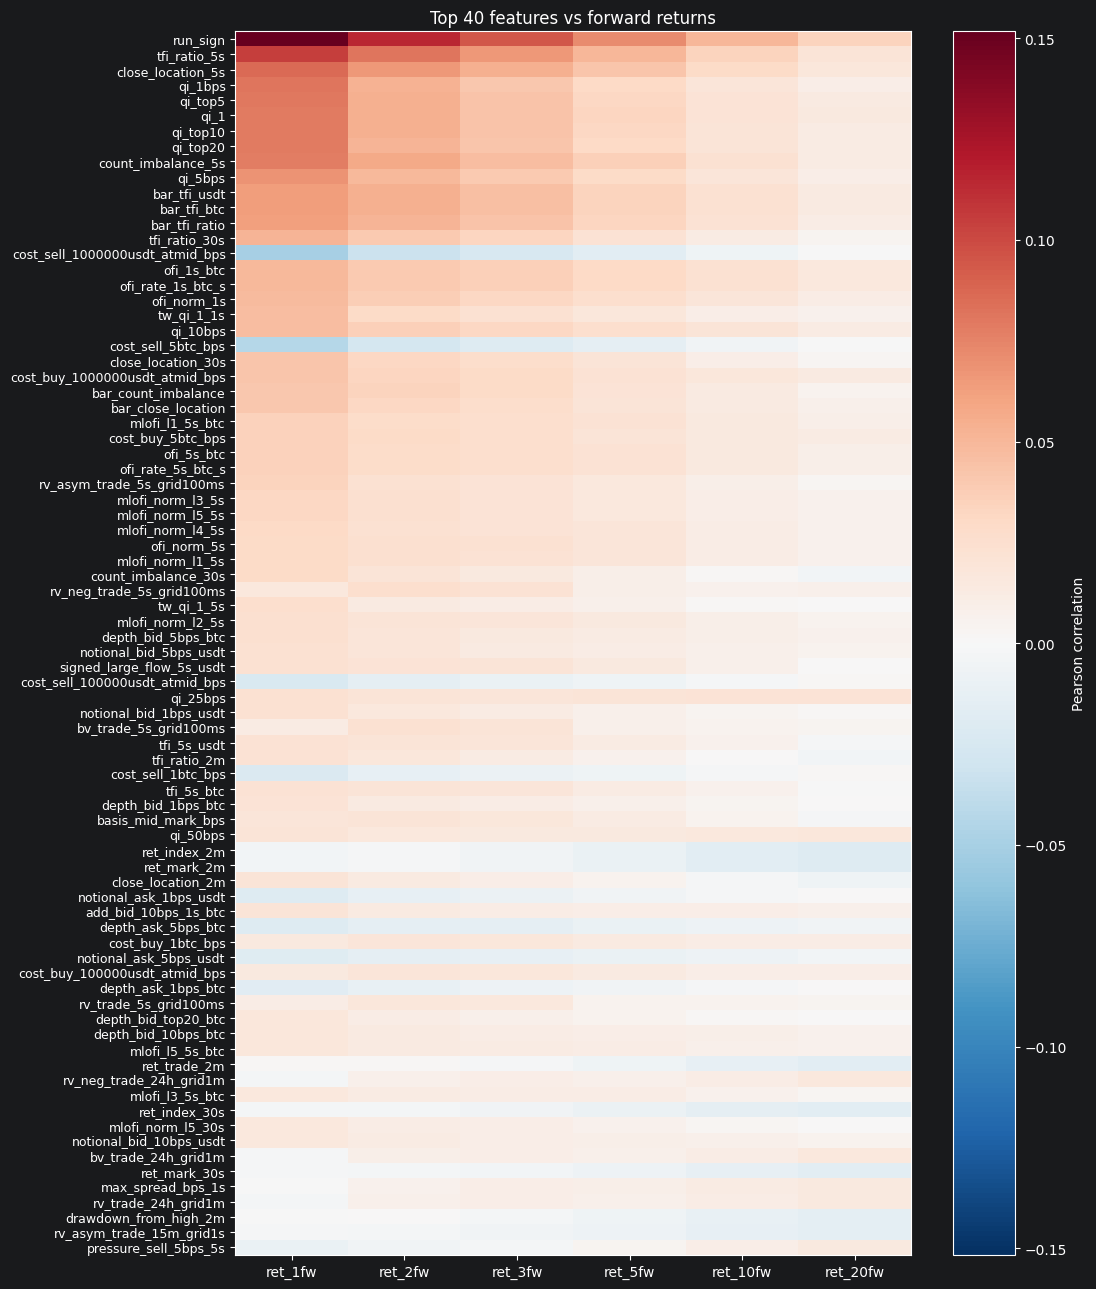

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 13))

matrix = top40_global[targets]

plt.imshow(
    matrix,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-matrix.abs().max().max(),
    vmax=matrix.abs().max().max()
)

plt.yticks(
    range(len(matrix)),
    matrix.index,
    fontsize=9
)

plt.xticks(
    range(len(targets)),
    targets
)

plt.colorbar(label="Pearson correlation")
plt.title("Top 40 features vs forward returns")
plt.tight_layout()
plt.show()

,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
decile,,,,,,
0.0,-0.575,-0.596,-0.569,-0.587,-0.589,-0.584
1.0,-0.427,-0.388,-0.374,-0.376,-0.380,-0.365
2.0,-0.214,-0.182,-0.193,-0.202,-0.195,-0.175
3.0,-0.111,-0.097,-0.102,-0.081,-0.051,-0.055
4.0,-0.042,-0.020,-0.031,-0.042,-0.062,-0.052
5.0,0.018,0.005,-0.005,-0.010,-0.042,-0.119
6.0,0.126,0.111,0.096,0.096,0.131,0.108
7.0,0.243,0.212,0.222,0.223,0.203,0.190
8.0,0.400,0.343,0.341,0.320,0.288,0.236


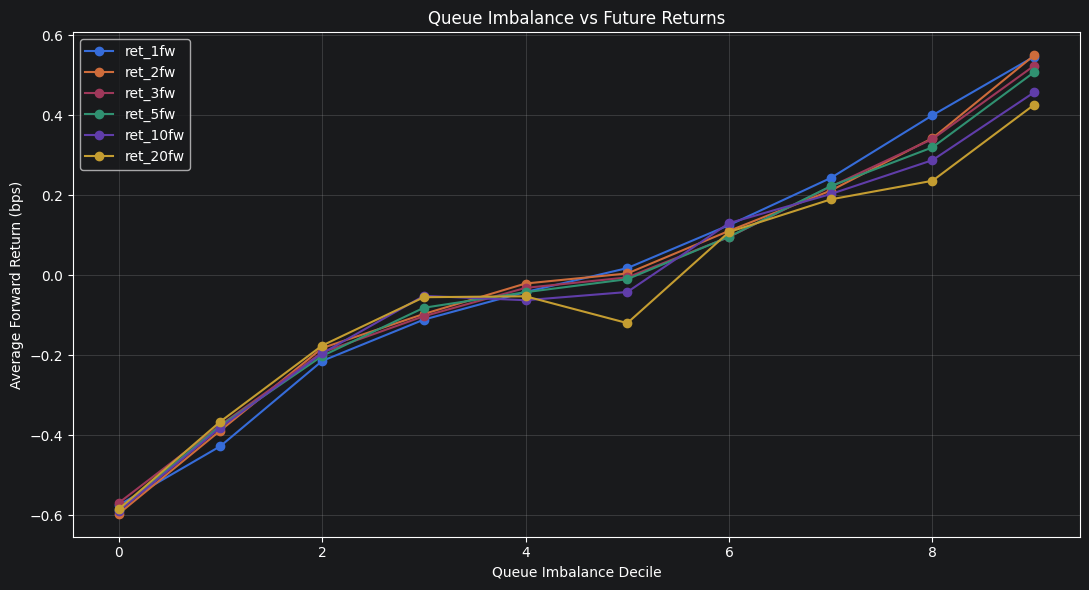

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

feature = "qi_top10"
targets = ["ret_1fw", "ret_2fw", "ret_3fw",
           "ret_5fw", "ret_10fw", "ret_20fw"]

data = df[[feature] + targets].copy()

data["decile"] = pd.qcut(
    data[feature],
    q=10,
    labels=False,
    duplicates="drop"
)

# Randamente medii în basis points
result = (
    data.groupby("decile")[targets]
    .mean()
    .mul(10000)
)

display(result.round(3))

result.plot(
    figsize=(11, 6),
    marker="o"
)

plt.xlabel("Queue Imbalance Decile")
plt.ylabel("Average Forward Return (bps)")
plt.title("Queue Imbalance vs Future Returns")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
feature = "qi_top10"
horizons = [1, 2, 3, 5, 10, 20]
targets = [f"ret_{h}fw" for h in horizons]

data = df.sort_values("decision_time_ns").copy()

split = int(len(data) * 0.8)

train = data.iloc[:split - max(horizons)].copy()
test = data.iloc[split:].copy()

_, bins = pd.qcut(
    train[feature].dropna(),
    q=10,
    retbins=True,
    duplicates="drop"
)

bins[0] = -np.inf
bins[-1] = np.inf

test["decile"] = pd.cut(
    test[feature],
    bins=bins,
    labels=False,
    include_lowest=True
)

result = (
    test.groupby("decile")[targets]
    .mean()
    .mul(10_000)
)

print("OUT-OF-SAMPLE DECILE RETURNS")
display(result.round(4))

low, high = result.index.min(), result.index.max()

spread = result.loc[high] - result.loc[low]

print("\nSPREAD EXTREME DECILES (bps)")
display(spread.round(4))

OUT-OF-SAMPLE DECILE RETURNS


,ret_1fw,ret_2fw,ret_3fw,ret_5fw,ret_10fw,ret_20fw
decile,,,,,,
0.0,-0.6329,-0.6395,-0.6090,-0.6063,-0.5930,-0.4876
1.0,-0.4620,-0.4001,-0.3762,-0.3530,-0.2916,-0.1733
2.0,-0.2181,-0.1985,-0.1894,-0.1458,-0.1000,-0.0370
3.0,-0.1229,-0.1059,-0.0784,-0.0350,0.0515,0.1978
4.0,-0.0553,-0.0441,-0.0526,-0.0615,0.0034,0.1006
5.0,0.0339,0.0463,0.0572,0.0432,0.0646,0.0353
6.0,0.1453,0.1368,0.1066,0.1220,0.2523,0.3414
7.0,0.2994,0.2723,0.2718,0.2737,0.2112,0.2112
8.0,0.4331,0.3805,0.3882,0.3766,0.3672,0.4343



SPREAD EXTREME DECILES (bps)


ret_1fw     1.2765
ret_2fw     1.3287
ret_3fw     1.2961
ret_5fw     1.3385
ret_10fw    1.3380
ret_20fw    1.3511
dtype: float32

## LightGBM

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "ret_5fw"
HORIZON = 1

# Economically motivated feature selection
features = [
    # Order book imbalance
    "qi_top10",
    "tw_qi_1_5s",
    "weighted_mid_offset_bps",

    # Order flow imbalance
    "ofi_norm_5s",
    "ofi_norm_30s",

    # Trade flow
    "bar_tfi_ratio",
    "tfi_ratio_5s",
    "tfi_ratio_30s",
    "count_imbalance_5s",

    # Liquidity and spread
    "spread_bps",
    "pressure_net_5bps_5s",

    # Price action
    "bar_return_log",
    "ret_trade_30s",
    "ret_trade_2m",

    # Volatility
    "rv_trade_30s_grid1s",
    "rv_trade_2m_grid1s",

    # Market activity
    "bar_duration_s",
    "notional_rate_ratio_5s_vs_24h",

    # Derivatives
    "oi_log_change_known_15m",
    "liq_imbalance_2m",
    "basis_mid_index_bps",

    # Time features
    "hour_of_day_sin",
    "hour_of_day_cos",
]

# Keep only available features
features = [f for f in features if f in df.columns]

# Chronological ordering
data = df.sort_values("decision_time_ns", kind="stable")

# Chronological train/validation/test split
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

if train_end <= HORIZON or val_end - train_end <= HORIZON:
    raise ValueError("Not enough observations for purged splits.")

# Purge observations whose forward target crosses a split boundary
train = data.iloc[:train_end - HORIZON]
val = data.iloc[train_end:val_end - HORIZON]
test = data.iloc[val_end:]

def prepare_split(split, selected_features):
    # Remove only rows with missing targets
    split = split.loc[split[TARGET].notna()]

    X = (
        split[selected_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float64")
    )

    # Convert log returns to basis points
    y = split[TARGET].astype("float64") * 10_000

    return X, y

X_train, y_train = prepare_split(train, features)
X_val, y_val = prepare_split(val, features)
X_test, y_test = prepare_split(test, features)

# Remove empty or constant features using train data only
usable = (
    X_train.notna().any()
    & (X_train.nunique(dropna=True) > 1)
)

features = usable[usable].index.tolist()

X_train = X_train[features]
X_val = X_val[features]
X_test = X_test[features]

# All preprocessing steps are fitted exclusively on training data
model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# Predictions
pred_train = model.predict(X_train)
pred_val = model.predict(X_val)
pred_test = model.predict(X_test)

print(f"Train: {len(X_train):,}")
print(f"Validation: {len(X_val):,}")
print(f"Test: {len(X_test):,}")
print(f"Features: {len(features)}")

Train: 961,909
Validation: 207,421
Test: 207,858
Features: 23


In [13]:
def evaluate_regression(y_true, y_pred, baseline_mean):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    baseline_pred = np.full_like(
        y_true, baseline_mean, dtype=float
    )

    ic = (
        np.corrcoef(y_true, y_pred)[0, 1]
        if np.std(y_pred) > 0 and np.std(y_true) > 0
        else np.nan
    )

    baseline_mse = mean_squared_error(
        y_true, baseline_pred
    )
    model_mse = mean_squared_error(y_true, y_pred)

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE_bps": np.sqrt(model_mse),
        "MAE_bps": mean_absolute_error(y_true, y_pred),
        "Pearson_IC": ic,
        "Direction_Acc": np.mean(
            np.sign(y_true) == np.sign(y_pred)
        ),
        "Baseline_RMSE_bps": np.sqrt(baseline_mse),
        "MSE_Improvement_%": (
            (1 - model_mse / baseline_mse) * 100
            if baseline_mse > 0 else np.nan
        )
    }


# The baseline is fixed using train data only
baseline_mean = y_train.mean()

results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_test, baseline_mean
    )
}).T

display(results.round(5))

,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.00411,9.75647,7.35366,0.06413,0.52899,9.77659,0.41121
Validation,0.00433,7.78084,5.97132,0.06958,0.53649,7.79817,0.44389
Test,0.00538,7.96833,6.26239,0.07398,0.53650,7.98990,0.53935


,mean_prediction_bps,mean_actual_bps,count
pred_decile,,,
0,-1.1193,-1.0118,17804
1,-0.8113,-0.6875,20256
2,-0.6004,-0.5122,21751
3,-0.3820,-0.3975,21430
4,-0.1576,-0.1035,21560
5,0.0666,0.1730,21561
6,0.2866,0.2927,21643
7,0.4953,0.5254,21307
8,0.6993,0.7046,20024


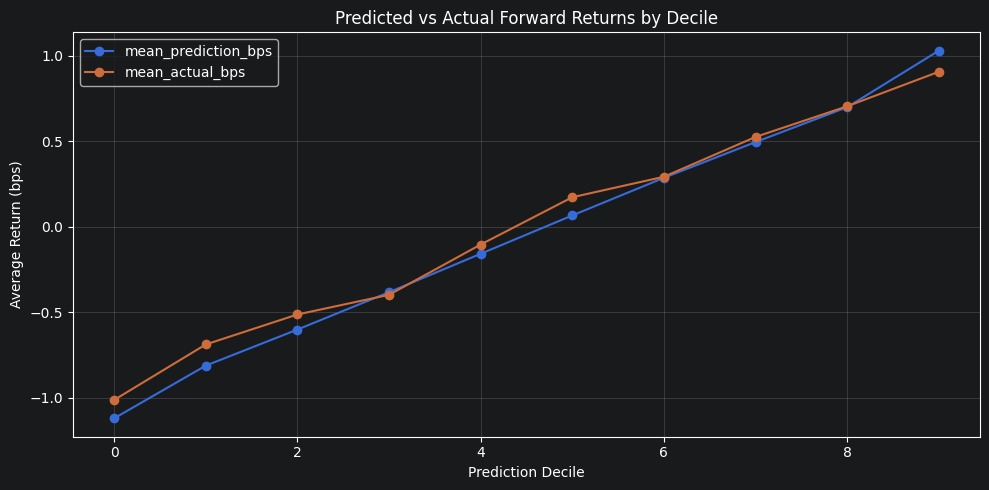

In [14]:
# Inspect the prediction distribution on the test set
predictions = pd.DataFrame({
    "actual_bps": y_test.to_numpy(),
    "predicted_bps": pred_test
}, index=X_test.index)

# Decile thresholds are fitted on validation predictions
_, bins = pd.qcut(
    pred_val,
    q=10,
    retbins=True,
    duplicates="drop"
)

bins[0] = -np.inf
bins[-1] = np.inf

predictions["pred_decile"] = pd.cut(
    predictions["predicted_bps"],
    bins=bins,
    labels=False,
    include_lowest=True
)

decile_results = (
    predictions.groupby("pred_decile")
    .agg(
        mean_prediction_bps=("predicted_bps", "mean"),
        mean_actual_bps=("actual_bps", "mean"),
        count=("actual_bps", "size")
    )
)

display(decile_results.round(4))

decile_results[
    ["mean_prediction_bps", "mean_actual_bps"]
].plot(
    figsize=(10, 5),
    marker="o",
    title="Predicted vs Actual Forward Returns by Decile"
)

plt.xlabel("Prediction Decile")
plt.ylabel("Average Return (bps)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## LightGBM

In [15]:
import lightgbm as lgb

# Prepare the same datasets used for Linear Regression
X_train_lgb = X_train.replace([np.inf, -np.inf], np.nan)
X_val_lgb = X_val.replace([np.inf, -np.inf], np.nan)
X_test_lgb = X_test.replace([np.inf, -np.inf], np.nan)

# Conservative configuration to reduce overfitting on noisy returns
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=500,
    colsample_bytree=0.85,
    reg_alpha=1.0,
    reg_lambda=10.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train with early stopping based only on validation performance
lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(100, verbose=False),
        lgb.log_evaluation(100)
    ]
)

# Generate predictions without modifying Linear Regression results
pred_lgb_train = lgb_model.predict(X_train_lgb)
pred_lgb_val = lgb_model.predict(X_val_lgb)
pred_lgb_test = lgb_model.predict(X_test_lgb)

print(f"Best iteration: {lgb_model.best_iteration_}")
print(f"Features: {X_train_lgb.shape[1]}")

[100]	valid_0's l2: 60.4431
[200]	valid_0's l2: 60.4538
Best iteration: 115
Features: 23


In [16]:
# Evaluate LightGBM using the same metrics and baseline
lgb_results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_lgb_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_lgb_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_lgb_test, baseline_mean
    )
}).T

print("=== LightGBM Results ===")
display(lgb_results.round(5))

# Compare against the existing Linear Regression results
comparison = pd.concat(
    {
        "Linear Regression": results,
        "LightGBM": lgb_results
    },
    names=["Model", "Split"]
)

print("=== Model Comparison ===")
display(comparison.round(5))

=== LightGBM Results ===


,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.00665,9.74405,7.34576,0.08577,0.53226,9.77659,0.66455
Validation,0.00598,7.77439,5.96911,0.07775,0.53467,7.79817,0.60900
Test,0.00596,7.96602,6.26471,0.07737,0.53356,7.98990,0.59699


=== Model Comparison ===


R2  RMSE_bps  MAE_bps  Pearson_IC  \
Model             Split                                                
Linear Regression Train       0.00411   9.75647  7.35366     0.06413   
                  Validation  0.00433   7.78084  5.97132     0.06958   
                  Test        0.00538   7.96833  6.26239     0.07398   
LightGBM          Train       0.00665   9.74405  7.34576     0.08577   
                  Validation  0.00598   7.77439  5.96911     0.07775   
                  Test        0.00596   7.96602  6.26471     0.07737   

                              Direction_Acc  Baseline_RMSE_bps  \
Model             Split                                          
Linear Regression Train             0.52899            9.77659   
                  Validation        0.53649            7.79817   
                  Test              0.53650            7.98990   
LightGBM          Train             0.53226            9.77659   
                  Validation        0.53467            7.79817   
                  Test              0.53356            7.98990   

                              MSE_Improvement_%  
Model             Split                          
Linear Regression Train                 0.41121  
                  Validation            0.44389  
                  Test                  0.53935  
LightGBM          Train                 0.66455  
                  Validation            0.60900  
                  Test                  0.59699

,feature,importance,importance_pct
6,tfi_ratio_5s,3146987.558,30.445
10,pressure_net_5bps_5s,1548104.984,14.977
13,ret_trade_2m,647590.899,6.265
2,weighted_mid_offset_bps,622012.778,6.018
0,qi_top10,549465.599,5.316
11,bar_return_log,521329.440,5.044
12,ret_trade_30s,506413.649,4.899
20,basis_mid_index_bps,429028.960,4.151
5,bar_tfi_ratio,416327.740,4.028
15,rv_trade_2m_grid1s,372516.530,3.604


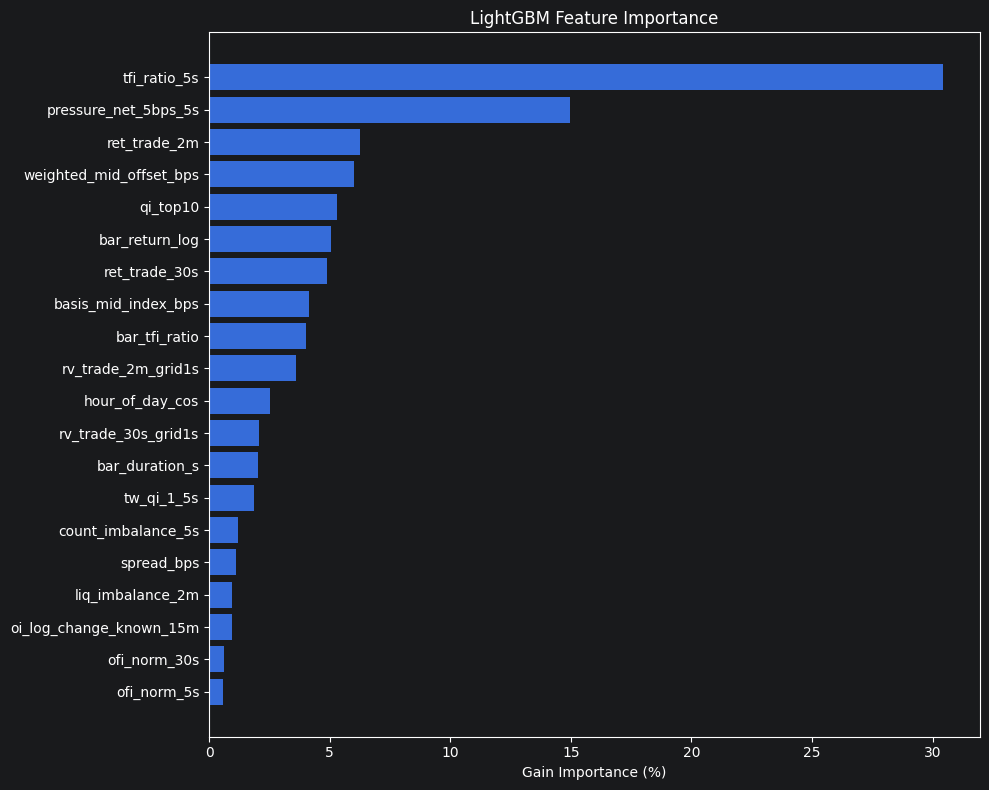

In [17]:
# Extract gain-based feature importance
importance = pd.DataFrame({
    "feature": X_train_lgb.columns,
    "importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance", ascending=False
)

importance["importance_pct"] = (
    importance["importance"]
    / importance["importance"].sum()
    * 100
)

display(importance.head(20).round(3))

# Plot the 20 most important features
top = importance.head(20).iloc[::-1]

plt.figure(figsize=(10, 8))
plt.barh(top["feature"], top["importance_pct"])
plt.xlabel("Gain Importance (%)")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## LightGBM with all the features

In [18]:
# Columns excluded from model inputs
metadata_cols = {
    "bar_id", "decision_time_ns", "eval_time_ns",
    "t_start_ns", "t_end_ns",
    "t_open_recv_ns", "t_close_recv_ns",
    "m_open_ms", "m_close_ms",
    "first_seq", "last_seq",
    "first_trade_id", "last_trade_id",
    "seg", "close_reason", "threshold_int",
    "complete", "feed_complete",
    "oi_reference_ts_ns"
}

# Exclude absolute price levels; keep returns, ratios and spreads
price_level_cols = {
    "bar_open", "bar_high", "bar_low", "bar_close",
    "bar_vwap", "last_trade_price",
    "best_bid", "best_ask", "mid",
    "mark_price", "index_price",
    "vwap_5s", "vwap_30s", "vwap_2m",
    "vwap_15m", "vwap_1h",
    "oi_value_price_implied"
}

# Select numerical features without using target correlations
all_features = [
    c for c in df.select_dtypes(include=["number", "bool"]).columns
    if c not in metadata_cols
    and c not in price_level_cols
    and not (c.startswith("ret_") and c.endswith("fw"))
    and not (c.startswith("duration_") and "fw" in c)
    and not c.startswith("markout_")
    and not c.startswith(("future_", "target_", "label_"))
    and c != "settle_est_index_bps_p2"
]

def prepare_full_X(split, index):
    return (
        split.loc[index, all_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float32")
    )

X_train_full = prepare_full_X(train, X_train.index)
X_val_full = prepare_full_X(val, X_val.index)
X_test_full = prepare_full_X(test, X_test.index)

# Filter constant or almost entirely unavailable features on train only
min_coverage = 0.05

valid_features = (
    (X_train_full.notna().mean() >= min_coverage)
    & (X_train_full.nunique(dropna=True) > 1)
)

selected_features = valid_features[valid_features].index.tolist()

X_train_full = X_train_full[selected_features]
X_val_full = X_val_full[selected_features]
X_test_full = X_test_full[selected_features]

print(f"Selected features: {len(selected_features)}")
print(f"Train: {len(X_train_full):,}")
print(f"Validation: {len(X_val_full):,}")
print(f"Test: {len(X_test_full):,}")

# Train LightGBM with additional regularization
lgb_full = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=1000,
    colsample_bytree=0.75,
    subsample=0.8,
    subsample_freq=1,
    reg_alpha=2.0,
    reg_lambda=20.0,
    max_bin=127,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_full.fit(
    X_train_full,
    y_train,
    eval_set=[(X_val_full, y_val)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(100, verbose=False),
        lgb.log_evaluation(100)
    ]
)

pred_full_train = lgb_full.predict(X_train_full)
pred_full_val = lgb_full.predict(X_val_full)
pred_full_test = lgb_full.predict(X_test_full)

full_results = pd.DataFrame({
    "Train": evaluate_regression(
        y_train, pred_full_train, baseline_mean
    ),
    "Validation": evaluate_regression(
        y_val, pred_full_val, baseline_mean
    ),
    "Test": evaluate_regression(
        y_test, pred_full_test, baseline_mean
    )
}).T

display(full_results.round(5))

# Compare the existing models against the full-feature model
comparison = pd.concat({
    "Linear Regression": results,
    "LightGBM Small": lgb_results,
    "LightGBM Full": full_results
})

display(comparison.round(5))

Selected features: 604
Train: 961,909
Validation: 207,421
Test: 207,858
[100]	valid_0's l2: 60.1336
[200]	valid_0's l2: 60.1517


,R2,RMSE_bps,MAE_bps,Pearson_IC,Direction_Acc,Baseline_RMSE_bps,MSE_Improvement_%
Train,0.01313,9.71221,7.32694,0.12298,0.54314,9.77659,1.31264
Validation,0.01120,7.75394,5.96017,0.10674,0.54323,7.79817,1.13115
Test,0.01167,7.94309,6.25209,0.10910,0.54316,7.98990,1.16829


R2  RMSE_bps  MAE_bps  Pearson_IC  \
Linear Regression Train       0.00411   9.75647  7.35366     0.06413   
                  Validation  0.00433   7.78084  5.97132     0.06958   
                  Test        0.00538   7.96833  6.26239     0.07398   
LightGBM Small    Train       0.00665   9.74405  7.34576     0.08577   
                  Validation  0.00598   7.77439  5.96911     0.07775   
                  Test        0.00596   7.96602  6.26471     0.07737   
LightGBM Full     Train       0.01313   9.71221  7.32694     0.12298   
                  Validation  0.01120   7.75394  5.96017     0.10674   
                  Test        0.01167   7.94309  6.25209     0.10910   

                              Direction_Acc  Baseline_RMSE_bps  \
Linear Regression Train             0.52899            9.77659   
                  Validation        0.53649            7.79817   
                  Test              0.53650            7.98990   
LightGBM Small    Train             0.53226            9.77659   
                  Validation        0.53467            7.79817   
                  Test              0.53356            7.98990   
LightGBM Full     Train             0.54314            9.77659   
                  Validation        0.54323            7.79817   
                  Test              0.54316            7.98990   

                              MSE_Improvement_%  
Linear Regression Train                 0.41121  
                  Validation            0.44389  
                  Test                  0.53935  
LightGBM Small    Train                 0.66455  
                  Validation            0.60900  
                  Test                  0.59699  
LightGBM Full     Train                 1.31264  
                  Validation            1.13115  
                  Test                  1.16829

,feature,gain,gain_pct
200,run_sign,5.098873e+06,29.6689
201,run_volume_btc,5.056937e+05,2.9425
42,rebound_from_low_5s,4.578799e+05,2.6643
40,close_location_5s,4.064579e+05,2.3651
199,run_length_trades,4.033903e+05,2.3472
374,qi_10bps,3.502739e+05,2.0381
379,qi_25bps,2.300494e+05,1.3386
41,drawdown_from_high_5s,2.095380e+05,1.2192
35,size_concentration_5s,1.892376e+05,1.1011
402,ofi_1s_btc,1.759238e+05,1.0236


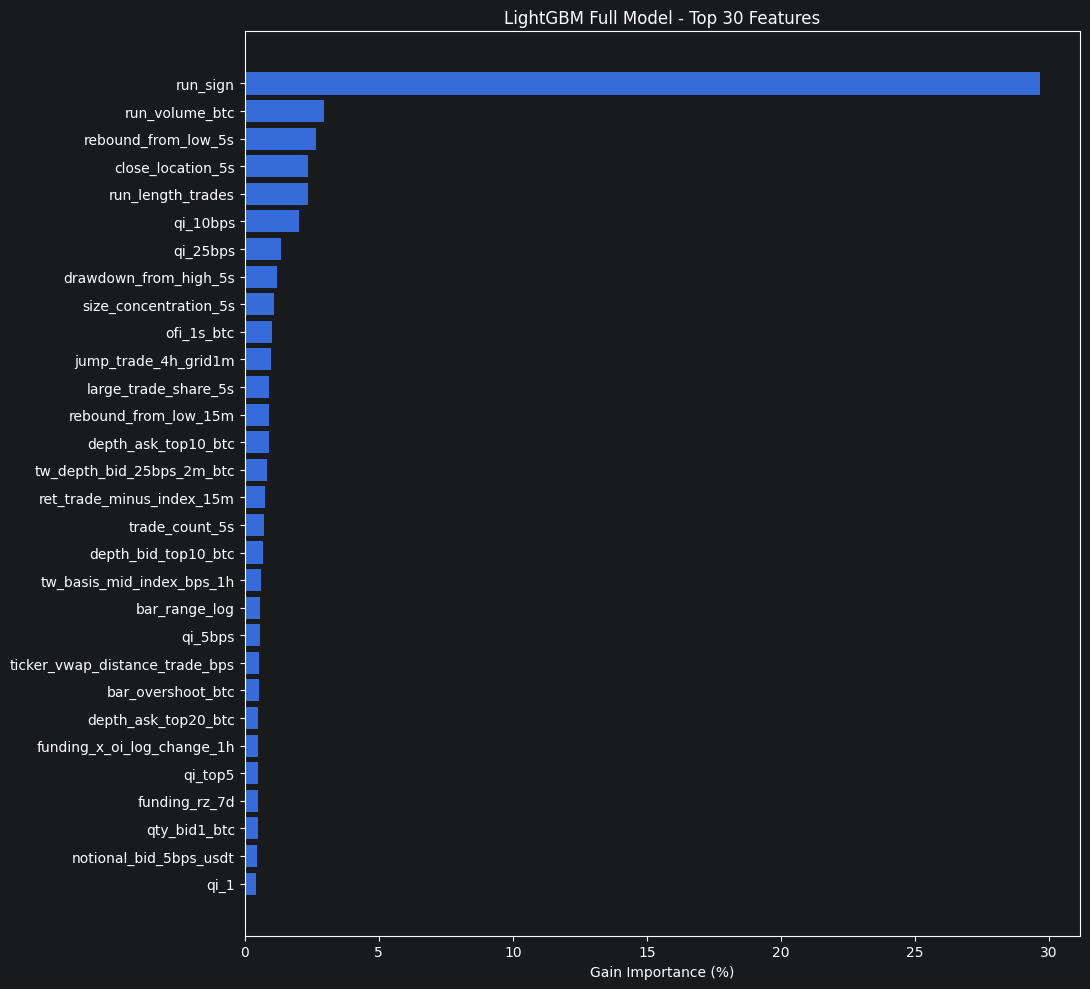

In [19]:
importance_full = pd.DataFrame({
    "feature": selected_features,
    "gain": lgb_full.booster_.feature_importance(
        importance_type="gain"
    )
})

importance_full["gain_pct"] = (
    importance_full["gain"]
    / importance_full["gain"].sum()
    * 100
)

importance_full = importance_full.sort_values(
    "gain", ascending=False
)

display(importance_full.head(50).round(4))

# Plot the 30 most important features
top = importance_full.head(30).iloc[::-1]

plt.figure(figsize=(11, 10))
plt.barh(top["feature"], top["gain_pct"])
plt.xlabel("Gain Importance (%)")
plt.title("LightGBM Full Model - Top 30 Features")
plt.tight_layout()
plt.show()

## Lag Features

In [ ]:
TARGET = "ret_1fw"
HORIZON = 1
LAGS = [1, 2, 3, 5, 10]

# Use "time" for time bars and "volume" for volume bars
BAR_TYPE = "time"

# Features whose historical evolution may contain predictive information
lag_features = [
    # Order book imbalance
    "qi_top10",
    "qi_1",
    "weighted_mid_offset_bps",
    "tw_qi_1_5s",

    # Order flow
    "ofi_norm_5s",
    "ofi_norm_30s",
    "ofi_norm_2m",

    # Trade flow
    "tfi_ratio_5s",
    "tfi_ratio_30s",
    "bar_tfi_ratio",
    "run_sign",

    # Price dynamics
    "bar_return_log",
    "ret_trade_30s",
    "ret_trade_2m",

    # Liquidity
    "spread_bps",
    "pressure_net_5bps_5s",
    "depth_bid_5bps_btc",
    "depth_ask_5bps_btc",

    # Volatility
    "rv_trade_30s_grid1s",
    "rv_trade_2m_grid1s",

    # Market activity
    "bar_duration_s",
    "notional_rate_ratio_5s_vs_24h",

    # Derivatives
    "basis_mid_index_bps",
    "oi_log_change_known_15m",
    "liq_imbalance_2m",
]

# Sort observations chronologically
data = df.sort_values("decision_time_ns", kind="stable").copy()

if not data.index.is_unique:
    raise ValueError("DataFrame index must be unique.")

# Reuse the feature universe from the previous full LightGBM experiment
base_features = [
    c for c in dict.fromkeys(all_features)
    if c in data.columns
    and pd.api.types.is_numeric_dtype(data[c])
    and c != TARGET
    and not (c.startswith("ret_") and c.endswith("fw"))
    and not (c.startswith("duration_") and "fw" in c)
    and not c.startswith("markout_")
    and not c.startswith(("future_", "target_", "label_"))
]

lag_features = [c for c in lag_features if c in base_features]

# Check chronological continuity
if "bar_id" in data.columns:
    ids = data["bar_id"].to_numpy(dtype=np.int64)
elif data.index.name == "bar_id":
    ids = data.index.to_numpy(dtype=np.int64)
else:
    raise ValueError("bar_id must be a column or the DataFrame index.")

n = len(data)

breaks = np.zeros(n, dtype=bool)
breaks[1:] = ids[1:] != ids[:-1] + 1

# Prevent lag features from crossing dataset segments
if "seg" in data.columns:
    seg = data["seg"].to_numpy()
    breaks[1:] |= seg[1:] != seg[:-1]

# Time bars must be temporally contiguous
if BAR_TYPE == "time":
    starts = data["t_start_ns"].to_numpy()
    ends = data["t_end_ns"].to_numpy()
    breaks[1:] |= starts[1:] != ends[:-1]

segment_id = np.cumsum(breaks)

# Generate historical features
lag_columns = {}

for feature in lag_features:
    values = data[feature].to_numpy(dtype=np.float32)

    for lag in LAGS:
        shifted = np.full(n, np.nan, dtype=np.float32)

        # A historical feature is valid only within the same segment
        valid = segment_id[lag:] == segment_id[:-lag]

        shifted[lag:] = np.where(
            valid,
            values[:-lag],
            np.nan
        )

        lag_columns[f"{feature}_lag{lag}"] = shifted

lag_df = pd.DataFrame(lag_columns, index=data.index)

print(f"Base features: {len(base_features)}")
print(f"Historical features: {len(lag_features)}")
print(f"New lag features: {lag_df.shape[1]}")
print(f"Total candidate features: {len(base_features) + lag_df.shape[1]}")

In [ ]:
# Chronological split
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Purge observations whose targets overlap the following split
train_stop = train_end - HORIZON
val_stop = val_end - HORIZON

if train_stop <= 0 or val_stop <= train_end:
    raise ValueError("Insufficient observations for purged splits.")

# Remove constant and low-coverage features based on training data only
train_base = (
    data.iloc[:train_stop][base_features]
    .replace([np.inf, -np.inf], np.nan)
)

valid_features = (
    (train_base.notna().mean() >= 0.05)
    & (train_base.nunique(dropna=True) > 1)
)

base_features = valid_features[valid_features].index.tolist()

def prepare_dataset(start, stop):
    subset = data.iloc[start:stop]

    # Keep observations with valid regression targets
    mask = (
        subset[TARGET].notna()
        & np.isfinite(subset[TARGET])
    )

    subset = subset.loc[mask]

    X_base = (
        subset[base_features]
        .replace([np.inf, -np.inf], np.nan)
        .astype("float32")
    )

    X_lags = (
        lag_df.loc[subset.index]
        .replace([np.inf, -np.inf], np.nan)
    )

    X_augmented = pd.concat([X_base, X_lags], axis=1)

    # Convert log returns to basis points
    y = subset[TARGET].to_numpy(dtype=np.float64) * 10_000

    return X_base, X_augmented, y


Xtr_base, Xtr_lag, ytr = prepare_dataset(0, train_stop)
Xva_base, Xva_lag, yva = prepare_dataset(train_end, val_stop)
Xte_base, Xte_lag, yte = prepare_dataset(val_end, n)

print("Dataset sizes:")
print(f"Train: {len(ytr):,}")
print(f"Validation: {len(yva):,}")
print(f"Test: {len(yte):,}")

print(f"\nBaseline features: {Xtr_base.shape[1]}")
print(f"Augmented features: {Xtr_lag.shape[1]}")

In [26]:
params = dict(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    min_child_samples=1000,
    colsample_bytree=0.75,
    subsample=0.8,
    subsample_freq=1,
    reg_alpha=2.0,
    reg_lambda=20.0,
    max_bin=127,
    random_state=42,
    n_jobs=4,
    verbosity=-1,
    force_col_wise=True,
    histogram_pool_size=256,
)


def train_model(with_lags):
    # Only one pair of train/val matrices exists at a time.
    Xtr = make_matrix(train_pos, with_lags)
    Xva = make_matrix(val_pos, with_lags)
    feature_names = all_augmented_names if with_lags else base_features
    print(f"Fitting {'lags' if with_lags else 'baseline'}: "
          f"Xtr={Xtr.nbytes / 2**30:.2f} GiB, Xva={Xva.nbytes / 2**30:.2f} GiB")
    model = lgb.LGBMRegressor(**params)
    model.fit(
        Xtr, ytr,
        eval_set=[(Xva, yva)],
        eval_metric="l2",
        feature_name=feature_names,
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    del Xtr, Xva
    gc.collect()
    return model


def evaluate_chunks(model, start, stop, with_lags, sampled_pos=None):
    """Evaluate full validation/test without ever materializing a full X."""
    ys, predictions = [], []
    if sampled_pos is None:
        batches = (
            np.arange(begin, min(begin + PREDICT_CHUNK_ROWS, stop), dtype=np.int64)
            for begin in range(start, stop, PREDICT_CHUNK_ROWS)
        )
    else:
        batches = (
            sampled_pos[i:i + PREDICT_CHUNK_ROWS]
            for i in range(0, len(sampled_pos), PREDICT_CHUNK_ROWS)
        )
    for pos in batches:
        src = src_pos(pos)
        pos = pos[np.isfinite(target_values[src])]
        if not len(pos):
            continue
        X = make_matrix(pos, with_lags)
        predictions.append(model.booster_.predict(X, num_threads=4))
        ys.append(target_values[src_pos(pos)] * 10_000)
        del X
    if not ys:
        raise ValueError("No valid targets in requested evaluation split")
    y = np.concatenate(ys)
    pred = np.concatenate(predictions)
    return evaluate_regression(y, pred, baseline_mean)


model_base = train_model(with_lags=False)
base_results = pd.DataFrame({
    "Train": evaluate_chunks(model_base, 0, train_stop, False, sampled_pos=train_pos),
    "Validation": evaluate_chunks(model_base, train_end, val_stop, False),
    "Test": evaluate_chunks(model_base, val_end, n, False),
}).T
print("Baseline best iteration:", model_base.best_iteration_)
gc.collect()

model_lag = train_model(with_lags=True)
lag_results = pd.DataFrame({
    "Train": evaluate_chunks(model_lag, 0, train_stop, True, sampled_pos=train_pos),
    "Validation": evaluate_chunks(model_lag, train_end, val_stop, True),
    "Test": evaluate_chunks(model_lag, val_end, n, True),
}).T
print("Lag best iteration:", model_lag.best_iteration_)
gc.collect()

Fitting baseline: Xtr=0.43 GiB, Xva=0.11 GiB
Baseline best iteration: 171
Fitting lags: Xtr=0.52 GiB, Xva=0.13 GiB
Lag best iteration: 171


312

In [27]:
comparison = pd.concat(
    {"Baseline": base_results, "With Lags": lag_results},
    names=["Model", "Split"],
)
display(comparison.round(5))

for split in ["Validation", "Test"]:
    print(f"\n=== {split.upper()} IMPROVEMENT ===")
    for metric in ["R2", "Pearson_IC", "Direction_Acc"]:
        improvement = lag_results.loc[split, metric] - base_results.loc[split, metric]
        print(f"{metric}: {improvement:+.6f}")

R2  RMSE_bps  MAE_bps  Pearson_IC  Direction_Acc  \
Model     Split                                                               
Baseline  Train       0.04654   4.23743  3.07981     0.22199        0.58630   
          Validation  0.04634   3.35812  2.47441     0.21553        0.58952   
          Test        0.04759   3.47745  2.60846     0.21918        0.58999   
With Lags Train       0.04654   4.23743  3.07981     0.22199        0.58630   
          Validation  0.04634   3.35812  2.47441     0.21553        0.58952   
          Test        0.04759   3.47745  2.60846     0.21918        0.58999   

                      Baseline_RMSE_bps  MSE_Improvement_%  
Model     Split                                             
Baseline  Train                 4.33963            4.65428  
          Validation            3.43877            4.63560  
          Test                  3.56327            4.75910  
With Lags Train                 4.33963            4.65428  
          Validation            3.43877            4.63560  
          Test                  3.56327            4.75910


=== VALIDATION IMPROVEMENT ===
R2: +0.000000
Pearson_IC: +0.000000
Direction_Acc: +0.000000

=== TEST IMPROVEMENT ===
R2: +0.000000
Pearson_IC: +0.000000
Direction_Acc: +0.000000
